### Import required libraries  
Basic libraries used for data processing and visualization.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import itertools
from collections import defaultdict
import time

### Load the dataset  
Read the transaction data from the CSV file into a pandas DataFrame.

In [68]:
df = pd.read_csv("transaction_data.csv")

In [69]:
df

,Product,Product Category (Enhanced Ecommerce),Transaction ID,Unique Purchases,Product Revenue
0,3.7V 3400mah LIION 12.6WH,Battery/Consumer Rechargeable,EC0043605902,47,"$1,597.53"
1,3V PHOTO LITHIUM,Battery/Primary Other,EC0043507670,47,"$1,246.44"
2,12V 11.2AH 225CCA AGM 12/0,Battery/Powersports,EC0043504182,41,"$4,714.59"
3,12V 12AH 165CCA FLOODED 6/0,Battery/Powersports,EC0043503186,39,"$2,456.61"
4,12V 12AH 210CCA AGM 12/0,Battery/Powersports,EC0043406547,34,"$3,570.00"
...,...,...,...,...,...
92245,ZUS SMART VEHICLE HEALTH MONITOR MINI,Bulb - Controls/Smart Home,EC0043404746,1,$9.97
92246,ZUS SMART VEHICLE HEALTH MONITOR MINI,Bulb - Controls/Smart Home,EC0043803104,1,$15.99
92247,ZUS SMART VEHICLE HEALTH MONITOR MINI,Bulb - Controls/Smart Home,EC0043804320,1,$15.99
92248,ZUS SMART VEHICLE HEALTH MONITOR MINI,Bulb - Controls/Smart Home,EC0044001978,1,$15.99


### Inspect dataset structure  
Displays the dimensions of the dataset and detailed information about columns and data types.

In [70]:
df.shape

(92250, 5)

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92250 entries, 0 to 92249
Data columns (total 5 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   Product                                92250 non-null  object
 1   Product Category (Enhanced Ecommerce)  92250 non-null  object
 2   Transaction ID                         92250 non-null  object
 3   Unique Purchases                       92250 non-null  int64 
 4   Product Revenue                        92250 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.5+ MB


### Count unique transactions and products  
Calculates how many distinct transaction IDs and product types exist in the dataset.

In [72]:
print("Unique Transaction IDs:", df['Transaction ID'].nunique())
print("Unique Products:", df['Product'].nunique())

Unique Transaction IDs: 83014
Unique Products: 2415


### Check for missing values  
Displays the number of missing entries in each column of the dataset.

In [73]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Product                                  0
Product Category (Enhanced Ecommerce)    0
Transaction ID                           0
Unique Purchases                         0
Product Revenue                          0
dtype: int64


### Compute transaction lengths  
Groups rows by transaction ID and calculates the average number of items per transaction.


The average transaction length is approximately 1.11 items, indicating that most transactions contain only a single product. This suggests the dataset is highly sparse and may limit the discovery of multi-item frequent patterns.

In [74]:
transaction_lengths = df.groupby('Transaction ID').size()
print("\nAverage number of items per transaction:", transaction_lengths.mean())


Average number of items per transaction: 1.1112583419664153


### Check for duplicate rows  
Counts how many rows in the dataset are exact duplicates.

In [75]:
df.duplicated().sum()

np.int64(0)

### Convert product revenue to numeric  
Removes currency symbols and commas from the revenue column and converts it to a float.

In [76]:
df["Product Revenue Float"] = (
    df["Product Revenue"]
    .replace(r'[\$,]', '', regex=True)
    .astype(float)
)

### Transaction length statistics  
Calculates the average, minimum, and maximum number of items per transaction.

Most transactions contain only one item, and although the maximum reaches 37 items, such cases are rare. This confirms that the dataset is sparse, which may reduce the likelihood of discovering larger frequent itemsets.

In [77]:
transaction_lengths = df.groupby("Transaction ID")["Product"].count()

avg_length = transaction_lengths.mean()
min_length = transaction_lengths.min()
max_length = transaction_lengths.max()

print("Transaction Length Statistics")
print("Average items per transaction:", avg_length)
print("Min items in a transaction:", min_length)
print("Max items in a transaction:", max_length)

Transaction Length Statistics
Average items per transaction: 1.1112583419664153
Min items in a transaction: 1
Max items in a transaction: 37


### List the most frequent items  
Computes item frequencies and prints the top 10 most commonly purchased products.

In [78]:
item_frequency = df["Product"].value_counts().head(20)

print("Top 20 Most Frequent Items")
print(item_frequency)

Top 20 Most Frequent Items
Product
12V U1 L&amp;G 6                  2425
6V GC2 ULTRA GOLF 12              1684
AGM 12V 7AH .187 FASTON           1642
12V 18AH 310CCA AGM 12/0          1204
12V 31DT DURACELL ULTRA AGM 30    1118
AGM 12V 5AH .187 FASTON           1077
DC 12V 35AH J TERM                1005
12V 17.5AH 310 CCA                 996
1.5V IND AA ALK BULK               979
1.5V ALKAL                         977
12V 30AH 400 CCA                   940
12V U1R L&amp;G 6                  928
1.55V SVROX                        925
12V 27 MARINE DP 12                922
12V 24 MARINE DP 12                900
GRP 31 AGM DUAL X2 MARINE          816
12V 24F ULTRA GOLD 36              811
1.5V IND AAA ALK BULK              789
AGM 12V 12AH .250 FASTON           781
12V 65 ULTRA 24                    751
Name: count, dtype: int64


### Revenue statistics  
Generates summary statistics (count, mean, standard deviation, min, quartiles, max) for the product revenue column.

These values provide an overview of the revenue distribution, helping identify skewness, potential outliers, and general pricing patterns in the dataset.

In [79]:
revenue_stats = df["Product Revenue Float"].describe()
print("Revenue Statistics")
print(revenue_stats)

Revenue Statistics
count    92250.000000
mean       190.383006
std        297.407428
min          0.000000
25%         44.990000
50%        116.990000
75%        219.980000
max      14739.200000
Name: Product Revenue Float, dtype: float64


### Convert dataset into transaction lists  
Groups all products under each transaction ID and converts the grouped results into a list of item lists.

This structure is required for frequent pattern mining algorithms such as Apriori and FP-Growth, where each transaction must be represented as a list of purchased items.

In [80]:
transactions = (
    df.groupby("Transaction ID")["Product"]
    .apply(list)
    .tolist()
)

print("Total number of transactions:", len(transactions))
print("Example transaction:", transactions[0])

Total number of transactions: 83014
Example transaction: ['(not set)']


In [81]:
print(transactions)

[['(not set)'], ['(not set)'], ['(not set)'], ['<product name>'], ['3V LITHIUM CR2032 BULK', 'INSPECTOR POCKET LIGHT', 'Xtreme High Performance 12A-A Powersport Battery'], ['Duracell Ultra Gold Flooded 800CCA BCI Group 34 Car and Truck Battery'], ['Replacement Battery for Select Universal and Franklin Wireless Hotspots'], ['Duracell Ultra Flooded 680CCA BCI Group 48 Heavy Duty Battery'], ['Duracell Ultra Platinum AGM 800CCA BCI Group 94R Car and Truck Battery'], ['Duracell Ultra Flooded 1100CCA BCI Group 8D Heavy Duty Battery'], ['OEM replacement battery for baby monitors'], ['Duracell Ultra Gold Flooded 725CCA BCI Group 24F Car and Truck Battery'], ['NOCO GB20 Genius Boost Sport 12V 500A LITHIUM JUMP START'], ['Duracell Ultra 12V 8AH AGM SLA Battery with F1 Terminals'], ['Duracell Ultra 12V 18AH General Purpose AGM SLA Battery with M6 Nut and Bolt T'], ['Canon 3.7V 2760mAh Digital Camera Replacement Battery'], ['Xtreme 20CH-BS 12V 270CCA AGM Powersport Battery'], ['12V 24F X2POWER 60'

### Remove invalid product entries  
Filters out placeholder or meaningless product names such as "(not set)" or "<product name>" to ensure data quality before mining.

In [82]:
invalid_items = ["(not set)", "<product name>", "", " ", "  ", "None", "none"]

df_clean = df[~df["Product"].isin(invalid_items)]

In [83]:
transactions = (
    df_clean.groupby("Transaction ID")["Product"]
    .apply(list)
    .tolist()
)

print("Total number of transactions:", len(transactions))
print("Example transaction:", transactions[0])
print(transactions)

Total number of transactions: 83010
Example transaction: ['3V LITHIUM CR2032 BULK', 'INSPECTOR POCKET LIGHT', 'Xtreme High Performance 12A-A Powersport Battery']
[['3V LITHIUM CR2032 BULK', 'INSPECTOR POCKET LIGHT', 'Xtreme High Performance 12A-A Powersport Battery'], ['Duracell Ultra Gold Flooded 800CCA BCI Group 34 Car and Truck Battery'], ['Replacement Battery for Select Universal and Franklin Wireless Hotspots'], ['Duracell Ultra Flooded 680CCA BCI Group 48 Heavy Duty Battery'], ['Duracell Ultra Platinum AGM 800CCA BCI Group 94R Car and Truck Battery'], ['Duracell Ultra Flooded 1100CCA BCI Group 8D Heavy Duty Battery'], ['OEM replacement battery for baby monitors'], ['Duracell Ultra Gold Flooded 725CCA BCI Group 24F Car and Truck Battery'], ['NOCO GB20 Genius Boost Sport 12V 500A LITHIUM JUMP START'], ['Duracell Ultra 12V 8AH AGM SLA Battery with F1 Terminals'], ['Duracell Ultra 12V 18AH General Purpose AGM SLA Battery with M6 Nut and Bolt T'], ['Canon 3.7V 2760mAh Digital Camera R

### Identify frequent items based on a minimum support threshold  
Counts the occurrences of each product, displays the top 10 most frequent items, and selects items that appear at least a specified number of times (here, 20).

This step reduces noise by keeping only items with sufficient frequency, which helps improve the effectiveness and efficiency of frequent pattern mining.

In [84]:
item_counts = df_clean["Product"].value_counts()

print("Unique item count:", len(item_counts))
print("Most frequent 10 item:\n", item_counts.head(10))

min_support_count = 20

frequent_items = item_counts[item_counts >= min_support_count].index

print("\nNumber of item that bigger than threshold:", len(frequent_items))

df_freq = df_clean[df_clean["Product"].isin(frequent_items)]

Unique item count: 2413
Most frequent 10 item:
 Product
12V U1 L&amp;G 6                  2425
6V GC2 ULTRA GOLF 12              1684
AGM 12V 7AH .187 FASTON           1642
12V 18AH 310CCA AGM 12/0          1204
12V 31DT DURACELL ULTRA AGM 30    1118
AGM 12V 5AH .187 FASTON           1077
DC 12V 35AH J TERM                1005
12V 17.5AH 310 CCA                 996
1.5V IND AA ALK BULK               979
1.5V ALKAL                         977
Name: count, dtype: int64

Number of item that bigger than threshold: 556


### Transaction length comparison  
Compares the average number of items per transaction across three stages:
1. Original dataset  
2. After removing invalid product names  
3. After keeping only frequent items  

The average transaction length remains close to 1 in all stages, showing that transactions are dominated by single-item purchases. Even after filtering, the structure of the dataset does not significantly change, which indicates high sparsity and explains why multi-item frequent patterns are rare.

In [85]:
tx_len_original = df.groupby("Transaction ID")["Product"].count()
avg_orig = tx_len_original.mean()

tx_len_valid = df_clean.groupby("Transaction ID")["Product"].count()
avg_valid = tx_len_valid.mean()

tx_len_freq = df_freq.groupby("Transaction ID")["Product"].count()
avg_freq = tx_len_freq.mean()

print("===== Transaction Length Comparison =====")
print(f"Original average length: {avg_orig:.2f}")
print(f"After removing invalid items: {avg_valid:.2f}")
print(f"After frequent-item filtering: {avg_freq:.2f}")

print("\nStep 1 - Original number of transactions:", len(tx_len_original))
print("Step 2 - After removing invalid items:", len(tx_len_valid))
print("Step 3 - After frequent-item filtering:", len(tx_len_freq))

===== Transaction Length Comparison =====
Original average length: 1.11
After removing invalid items: 1.11
After frequent-item filtering: 1.10

Step 1 - Original number of transactions: 83014
Step 2 - After removing invalid items: 83010
Step 3 - After frequent-item filtering: 76576


In [86]:
transactions = (
    df_freq.groupby("Transaction ID")["Product"]
    .apply(list)
    .tolist()
)

print("Transaction Count:", len(transactions))
print("Example of transactions:")
for i in range(5):
  print(transactions[i])

Transaction Count: 76576
Example of transactions:
['3V LITHIUM CR2032 BULK', 'INSPECTOR POCKET LIGHT']
['12V 24F X2POWER 60']
['12V 35 ULTRA GOLD 36']
['6V LITHIUM ULTRA 1PK']
['12V 18AH AGM 1218NB']


## Visualizations



### Top categories by total revenue  
Aggregates total revenue for each product category and visualizes the top 10 categories with the highest revenue.

This chart highlights which product categories contribute the most to overall revenue, helping identify the most financially significant segments in the dataset.

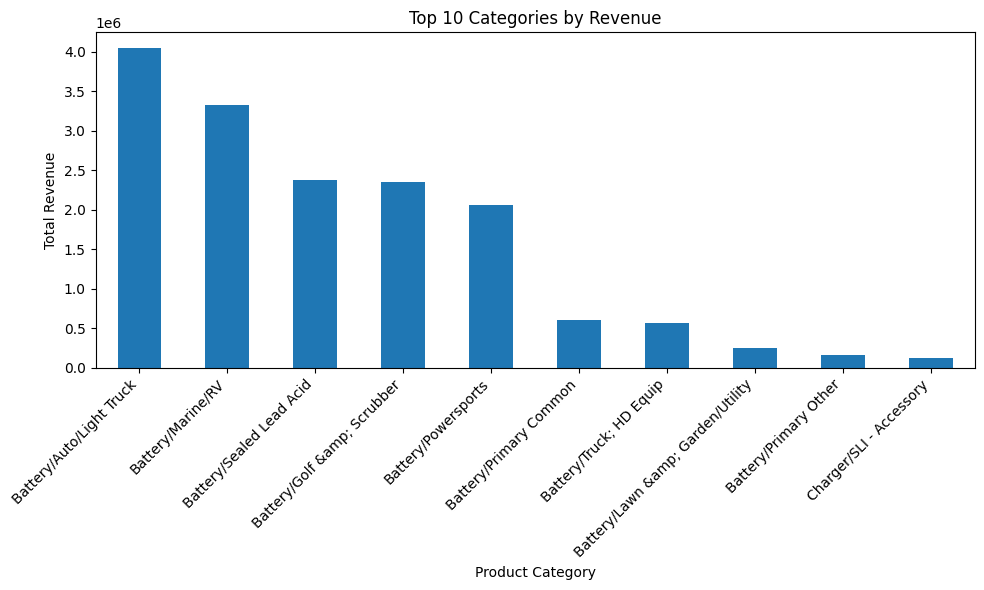

In [87]:
category_revenue = df_freq.groupby("Product Category (Enhanced Ecommerce)")["Product Revenue Float"].sum().sort_values(ascending=False)

top10 = category_revenue.head(10)

plt.figure(figsize=(10,6))
top10.plot(kind="bar")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.title("Top 10 Categories by Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Top 10 products by total revenue  
Calculates and visualizes the ten products that generate the highest total revenue.

This horizontal bar chart shows which individual products are the strongest revenue drivers, providing insight into product-level performance.

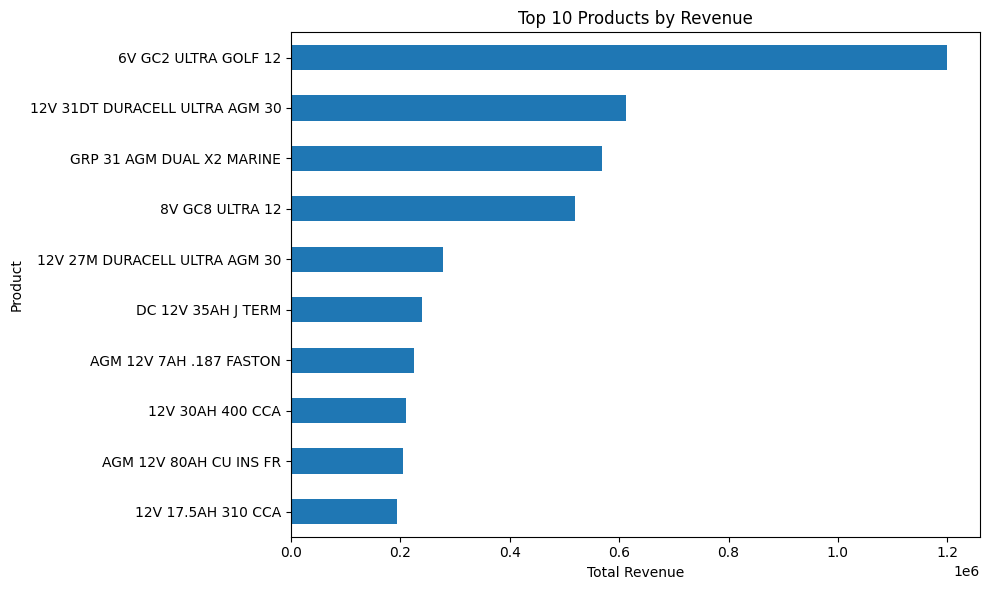

In [88]:
product_revenue = df_freq.groupby("Product")["Product Revenue Float"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
product_revenue.plot(kind="barh")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.title("Top 10 Products by Revenue")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Scatter plot: Unique Purchases vs. Product Revenue  
Visualizes the relationship between the number of unique purchases of a product and its total revenue.

This plot helps identify whether products with higher purchase counts tend to generate higher revenue, and can reveal outliers with unusually high or low performance.

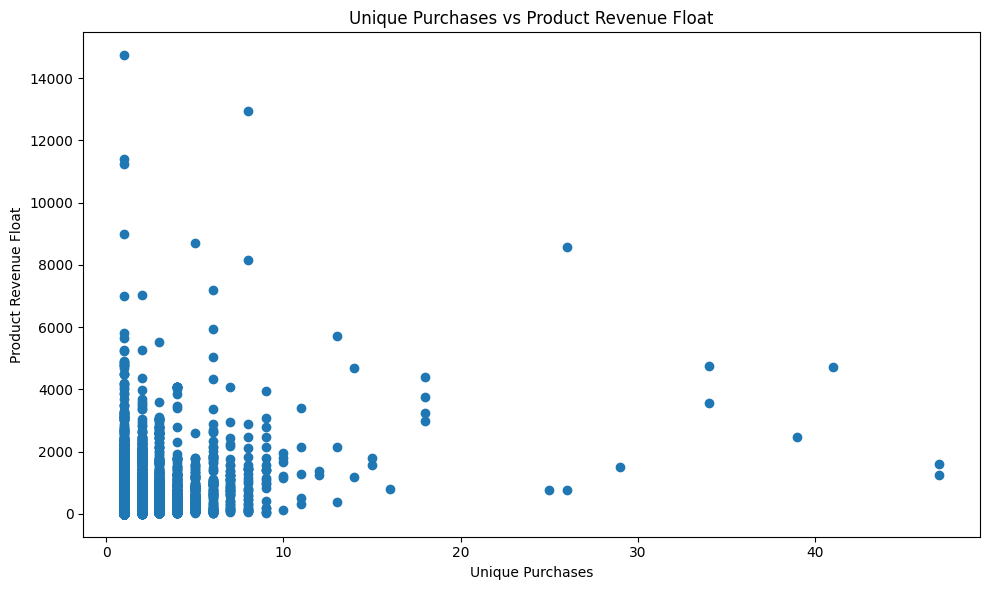

In [89]:
plt.figure(figsize=(10,6))
plt.scatter(df_freq["Unique Purchases"], df_freq["Product Revenue Float"])
plt.xlabel("Unique Purchases")
plt.ylabel("Product Revenue Float")
plt.title("Unique Purchases vs Product Revenue Float")
plt.tight_layout()
plt.show()

### Revenue share by top categories  
Calculates the total revenue for each category and visualizes the top six categories using a pie chart.

This chart provides a clear view of how revenue is distributed across the most profitable categories, showing which segments dominate overall earnings.

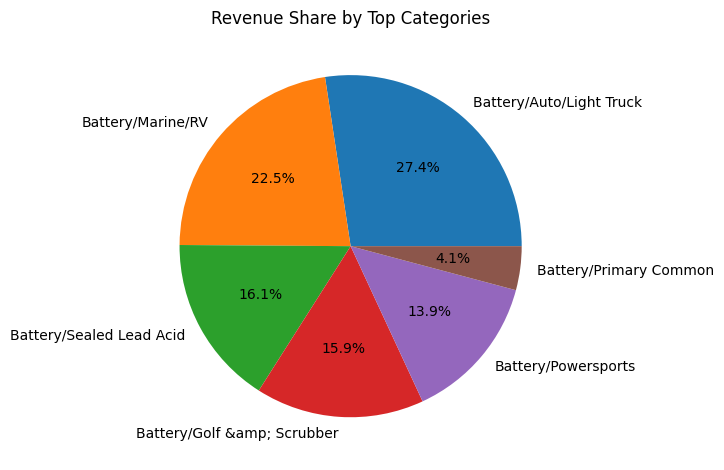

In [90]:
category_revenue = df_freq.groupby("Product Category (Enhanced Ecommerce)")["Product Revenue Float"].sum()
top_categories = category_revenue.sort_values(ascending=False).head(6)

plt.figure()
plt.pie(top_categories.values, labels=top_categories.index, autopct="%1.1f%%")
plt.title("Revenue Share by Top Categories")
plt.tight_layout()
plt.show()

### Distribution of product revenue  
Plots a histogram of the product revenue values to show how revenue amounts are distributed.

This visualization helps identify the overall shape of the revenue distribution, including skewness and the presence of extremely high or low revenue values.

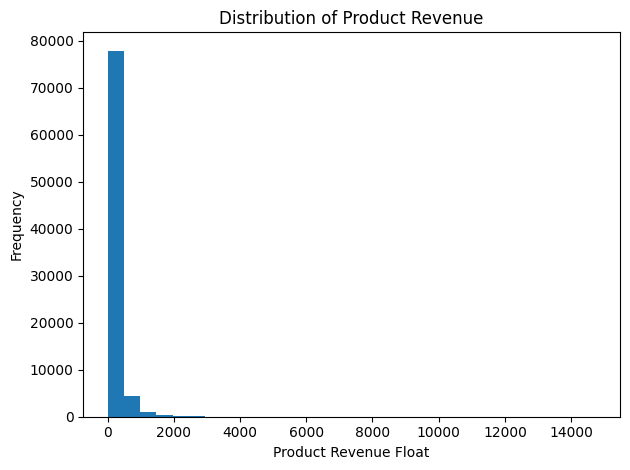

In [91]:
plt.figure()
plt.hist(df_freq["Product Revenue Float"], bins=30)
plt.xlabel("Product Revenue Float")
plt.ylabel("Frequency")
plt.title("Distribution of Product Revenue")
plt.tight_layout()
plt.show()

### Pareto chart for top 20 products by revenue  
Displays the total revenue of the top 20 products as bars and overlays the cumulative percentage curve.

This Pareto chart highlights which products contribute most to total revenue. A sharp rise in the cumulative curve indicates that a small subset of products accounts for the majority of revenue, reflecting the 80/20 rule.


The chart shows that revenue is heavily concentrated in a small number of products.  
The top product alone contributes more than 1.2 million in revenue, and the next few products also provide substantial amounts. As the cumulative curve indicates, only a handful of products account for a large portion of total revenue, demonstrating a classic Pareto (80/20) effect.  
This means that optimizing or focusing on a small number of key products could significantly impact overall business performance.

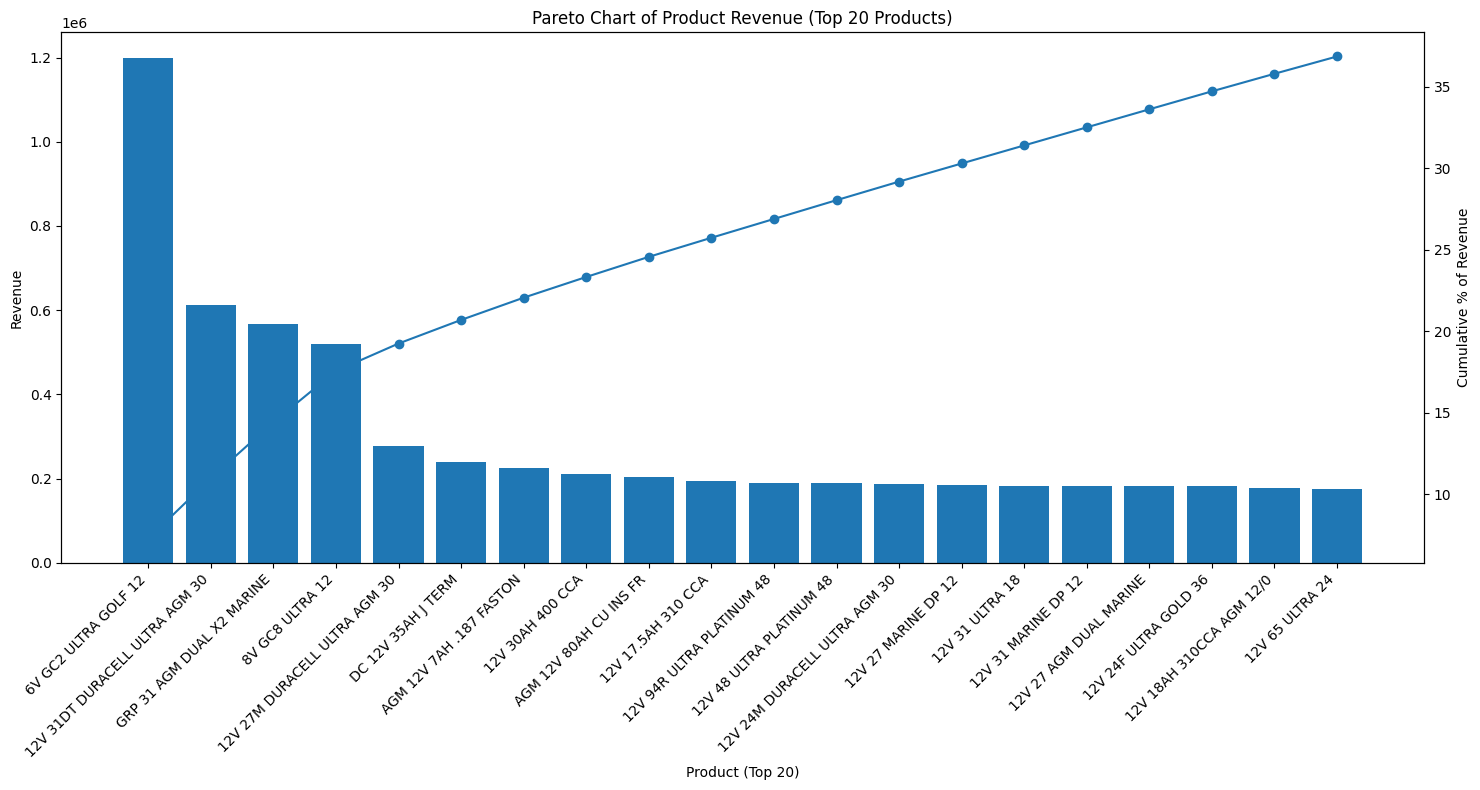

In [92]:
product_revenue = df_freq.groupby("Product")["Product Revenue Float"].sum().sort_values(ascending=False)

cum_percent = product_revenue.cumsum() / product_revenue.sum() * 100

top_n = 20
product_revenue_top = product_revenue.head(top_n)
cum_percent_top = cum_percent.head(top_n)

fig, ax1 = plt.subplots(figsize=(15,8))
ax1.bar(range(len(product_revenue_top)), product_revenue_top.values)
ax1.set_xlabel("Product (Top 20)")
ax1.set_ylabel("Revenue")
ax1.set_xticks(range(len(product_revenue_top)))
ax1.set_xticklabels(product_revenue_top.index, rotation=45, ha="right")

ax2 = ax1.twinx()
ax2.plot(range(len(cum_percent_top)), cum_percent_top.values, marker="o")
ax2.set_ylabel("Cumulative % of Revenue")

plt.title("Pareto Chart of Product Revenue (Top 20 Products)")
plt.tight_layout()
plt.show()

# Appriori

### Apriori helper functions  
- `get_support(itemset, transactions)`: Computes the relative support of a given itemset in the transaction list.  
- `generate_C1(transactions)`: Creates the initial candidate set C1 containing all unique 1-itemsets.  
- `prune_candidates(candidates, transactions, min_support)`: Filters candidates by support and returns only those that satisfy the minimum support threshold.  
- `generate_next_candidates(freq_itemsets, k)`: Joins frequent (k−1)-itemsets to generate k-itemset candidates (Apriori join step).

### Apriori algorithm implementation  
The `apriori(transactions, min_support)` function runs the full Apriori loop:
1. Builds C1 and prunes it to obtain L1 (frequent 1-itemsets).  
2. Iteratively generates candidate sets Ck, prunes them to obtain Lk, and collects all frequent itemsets.  
3. Stops when no more frequent itemsets are found and returns all frequent itemsets with their support values.

In [93]:
def get_support(itemset, transactions):
    count = 0
    for tx in transactions:
        if itemset.issubset(tx):
            count += 1
    return count / len(transactions)


def generate_C1(transactions):
    items = set()
    for tx in transactions:
        for item in tx:
            items.add(frozenset([item]))
    return list(items)


def prune_candidates(candidates, transactions, min_support):
    freq = {}
    for candidate in candidates:
        support = get_support(candidate, transactions)
        if support >= min_support:
            freq[candidate] = support
    return freq


def generate_next_candidates(freq_itemsets, k):
    freq_list = list(freq_itemsets.keys())
    candidates = []

    for i in range(len(freq_list)):
        for j in range(i + 1, len(freq_list)):
            L1 = list(freq_list[i])
            L2 = list(freq_list[j])

            L1.sort()
            L2.sort()

            if L1[:k-1] == L2[:k-1]:
                new_candidate = frozenset(freq_list[i] | freq_list[j])
                candidates.append(new_candidate)

    return candidates

In [94]:
def apriori(transactions, min_support):
    C1 = generate_C1(transactions)

    L1 = prune_candidates(C1, transactions, min_support)

    all_freq_itemsets = {}
    all_freq_itemsets.update(L1)

    Lk = L1
    k = 2

    while len(Lk) > 0:
        print(f"\n=== Iteration k={k} ===")

        Ck = generate_next_candidates(Lk, k)

        print(f"Candidates C{k}: {len(Ck)} adet")

        Lk = prune_candidates(Ck, transactions, min_support)

        print(f"Frequent L{k}: {len(Lk)} adet")

        all_freq_itemsets.update(Lk)
        k += 1

    return all_freq_itemsets

In [95]:
min_support = 0.01

frequent_itemsets = apriori(transactions, min_support)

print("\n===== Frequent Itemsets (support >= 0.01) =====")
for itemset, sup in frequent_itemsets.items():
    print(list(itemset), "→", round(sup, 4))


=== Iteration k=2 ===
Candidates C2: 0 adet
Frequent L2: 0 adet

===== Frequent Itemsets (support >= 0.01) =====
['1.5V IND AA ALK BULK'] → 0.0128
['12V 18AH 310CCA AGM 12/0'] → 0.0157
['AGM 12V 5AH .187 FASTON'] → 0.0141
['12V 17.5AH 310 CCA'] → 0.013
['1.5V ALKAL'] → 0.0127
['AGM 12V 7AH .187 FASTON'] → 0.0214
['12V U1R L&amp;G 6'] → 0.0121
['12V 24 MARINE DP 12'] → 0.0118
['12V 27 MARINE DP 12'] → 0.012
['12V 31DT DURACELL ULTRA AGM 30'] → 0.0146
['DC 12V 35AH J TERM'] → 0.0131
['12V 30AH 400 CCA'] → 0.0123
['GRP 31 AGM DUAL X2 MARINE'] → 0.0107
['6V GC2 ULTRA GOLF 12'] → 0.022
['12V 24F ULTRA GOLD 36'] → 0.0106
['12V U1 L&amp;G 6'] → 0.0317
['AGM 12V 12AH .250 FASTON'] → 0.0102
['1.5V IND AAA ALK BULK'] → 0.0103
['1.55V SVROX'] → 0.0121


In [96]:
for s in [0.01, 0.02, 0.03,0.04]:
    print("\n==============================")
    print(f"Running Apriori with min_support = {s}")
    result = apriori(transactions, s)
    print(f"Found {len(result)} frequent itemsets\n")

     # Eğer frequent itemset varsa bastır
    if len(result) > 0:
        print("Frequent itemsets:")
        for itemset, sup in sorted(result.items(), key=lambda x: x[1], reverse=True):
            print("  ", list(itemset), "→", round(sup, 4))
    else:
        print("No itemsets found with this support threshold.")


Running Apriori with min_support = 0.01

=== Iteration k=2 ===
Candidates C2: 0 adet
Frequent L2: 0 adet
Found 19 frequent itemsets

Frequent itemsets:
   ['12V U1 L&amp;G 6'] → 0.0317
   ['6V GC2 ULTRA GOLF 12'] → 0.022
   ['AGM 12V 7AH .187 FASTON'] → 0.0214
   ['12V 18AH 310CCA AGM 12/0'] → 0.0157
   ['12V 31DT DURACELL ULTRA AGM 30'] → 0.0146
   ['AGM 12V 5AH .187 FASTON'] → 0.0141
   ['DC 12V 35AH J TERM'] → 0.0131
   ['12V 17.5AH 310 CCA'] → 0.013
   ['1.5V IND AA ALK BULK'] → 0.0128
   ['1.5V ALKAL'] → 0.0127
   ['12V 30AH 400 CCA'] → 0.0123
   ['12V U1R L&amp;G 6'] → 0.0121
   ['1.55V SVROX'] → 0.0121
   ['12V 27 MARINE DP 12'] → 0.012
   ['12V 24 MARINE DP 12'] → 0.0118
   ['GRP 31 AGM DUAL X2 MARINE'] → 0.0107
   ['12V 24F ULTRA GOLD 36'] → 0.0106
   ['1.5V IND AAA ALK BULK'] → 0.0103
   ['AGM 12V 12AH .250 FASTON'] → 0.0102

Running Apriori with min_support = 0.02

=== Iteration k=2 ===
Candidates C2: 0 adet
Frequent L2: 0 adet
Found 3 frequent itemsets

Frequent itemsets:


The Apriori algorithm applied to the dataset produced only 1-item frequent itemsets and no frequent itemsets of size 2 or higher. This outcome is expected given the structure of the transactional data: the average transaction length is only 1.1, meaning that most transactions contain a single product and co-purchases are extremely rare. Because of this, candidate itemsets of size 2 (C₂) cannot be formed at sufficient frequency, causing Apriori to terminate after the first iteration. Using a minimum support threshold of 0.01, the algorithm identified 19 frequent single items. Increasing the support threshold to 0.02 reduced this number to 3, and at 0.05 no itemsets met the requirement. This demonstrates the strong sensitivity of Apriori to the support parameter: higher thresholds sharply reduce the number of patterns, while lower thresholds generate more frequent itemsets. From a computational perspective, Apriori’s runtime remained fast in this dataset because the lack of multi-item transactions prevented exponential growth in candidate generation. In denser datasets, Apriori’s complexity grows rapidly due to the combinatorial explosion of candidate itemsets, but in this case the algorithm remained efficient due to minimal joining in the L₁ → L₂ step. Overall, the discovered patterns reflect the sparsity of the transaction data, and the runtime characteristics illustrate Apriori’s dependence on both dataset density and support thresholds.

# FP-Growth

### FP-Growth implementation  

- `class FPTreeNode`: Defines a node in the FP-Tree, storing the item name, its count, a reference to the parent node, its children, and a node-link used to connect nodes with the same item.  
- `get_item_support(transactions)`: Computes the support count of each individual item across all transactions.  
- `build_fp_tree(transactions, min_support)`:  
  - Filters items that do not meet the minimum support threshold.  
  - Builds the FP-Tree by inserting each filtered transaction in descending order of item support.  
  - Maintains a header table that records each item’s total support and the first node in its node-link chain.  
- `find_prefix_paths(base_item, header_table)`: Traverses the node-link chain of a given item and extracts all prefix paths (with counts) that lead to that item in the FP-Tree.  
- `build_conditional_transactions(paths)`: Converts prefix paths into conditional transactions, replicating each path according to its count.  
- `fp_growth_recursive(header_table, min_support, prefix, frequent_itemsets, num_transactions)`:  
  - Recursively mines the FP-Tree from the bottom up.  
  - For each item, extends the current prefix, computes support, and if it passes the threshold, stores the frequent itemset.  
  - Builds conditional FP-Trees and continues mining until no more frequent itemsets can be found.  
- `fp_growth(transactions, min_support)`:  
  - Top-level function that builds the initial FP-Tree and header table.  
  - Calls the recursive mining procedure and returns all frequent itemsets with their support values.

In [97]:
class FPTreeNode:
    def __init__(self, item, count, parent):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}
        self.node_link = None

    def increment(self, count):
        self.count += count

In [98]:
def get_item_support(transactions):
    support = defaultdict(int)
    for tx in transactions:
        for item in tx:
            support[item] += 1
    return support

In [99]:
def build_fp_tree(transactions, min_support):
    item_support = get_item_support(transactions)
    num_transactions = len(transactions)

    min_support_count = min_support * num_transactions

    item_support = {
        item: count for item, count in item_support.items()
        if count >= min_support_count
    }

    if len(item_support) == 0:
        return None, None, None

    header_table = {
        item: [support, None]
        for item, support in sorted(
            item_support.items(),
            key=lambda x: x[1],
            reverse=True
        )
    }

    root = FPTreeNode(None, 0, None)


    for tx in transactions:
        filtered = [item for item in tx if item in item_support]

        if not filtered:
            continue

        filtered.sort(
            key=lambda item: item_support[item],
            reverse=True
        )

        current_node = root
        for item in filtered:
            if item in current_node.children:
                current_node.children[item].increment(1)
            else:
                new_node = FPTreeNode(item, 1, current_node)
                current_node.children[item] = new_node

                if header_table[item][1] is None:
                    header_table[item][1] = new_node
                else:
                    node = header_table[item][1]
                    while node.node_link is not None:
                        node = node.node_link
                    node.node_link = new_node

            current_node = current_node.children[item]

    return root, header_table, num_transactions

In [100]:
def find_prefix_paths(base_item, header_table):
    paths = []
    node = header_table[base_item][1]

    while node is not None:
        path = []
        parent = node.parent

        while parent is not None and parent.item is not None:
            path.append(parent.item)
            parent = parent.parent

        path = list(reversed(path))

        if len(path) > 0:
            paths.append((path, node.count))

        node = node.node_link

    return paths

In [101]:
def build_conditional_transactions(paths):
    conditional_transactions = []
    for path, count in paths:
        for _ in range(count):
            conditional_transactions.append(path)
    return conditional_transactions

In [102]:
def fp_growth_recursive(header_table, min_support, prefix, frequent_itemsets, num_transactions):
    items = sorted(header_table.items(), key=lambda x: x[1][0])

    for item, (support_count, node_link) in items:
        new_freq_itemset = prefix.copy()
        new_freq_itemset.add(item)

        support = support_count / num_transactions

        if support >= min_support:
          frequent_itemsets[frozenset(new_freq_itemset)] = support

        paths = find_prefix_paths(item, header_table)

        conditional_transactions = build_conditional_transactions(paths)

        cond_root, cond_header, _ = build_fp_tree(conditional_transactions, min_support)

        if cond_header is not None:
            fp_growth_recursive(cond_header, min_support, new_freq_itemset, frequent_itemsets, num_transactions)

In [103]:
def fp_growth(transactions, min_support):
    root, header_table, num_transactions = build_fp_tree(transactions, min_support)

    if header_table is None:
        return {}

    frequent_itemsets = {}
    fp_growth_recursive(header_table, min_support, prefix=set(), frequent_itemsets=frequent_itemsets, num_transactions=num_transactions)

    return frequent_itemsets

In [104]:
min_support = 0.01

fp_freq_itemsets = fp_growth(transactions, min_support)

print("===== FP-Growth Frequent Itemsets (support >= 0.01) =====")
for itemset, sup in fp_freq_itemsets.items():
    if sup >= min_support:
        print(list(itemset), "→", round(sup, 4))

===== FP-Growth Frequent Itemsets (support >= 0.01) =====
['AGM 12V 12AH .250 FASTON'] → 0.0102
['1.5V IND AAA ALK BULK'] → 0.0103
['12V 24F ULTRA GOLD 36'] → 0.0106
['GRP 31 AGM DUAL X2 MARINE'] → 0.0107
['12V 24 MARINE DP 12'] → 0.0118
['12V 27 MARINE DP 12'] → 0.012
['1.55V SVROX'] → 0.0121
['12V U1R L&amp;G 6'] → 0.0121
['12V 30AH 400 CCA'] → 0.0123
['1.5V ALKAL'] → 0.0128
['1.5V IND AA ALK BULK'] → 0.0128
['12V 17.5AH 310 CCA'] → 0.013
['DC 12V 35AH J TERM'] → 0.0131
['AGM 12V 5AH .187 FASTON'] → 0.0141
['12V 31DT DURACELL ULTRA AGM 30'] → 0.0146
['12V 18AH 310CCA AGM 12/0'] → 0.0157
['AGM 12V 7AH .187 FASTON'] → 0.0214
['6V GC2 ULTRA GOLF 12'] → 0.022
['12V U1 L&amp;G 6'] → 0.0317


In [105]:
for s in [0.01, 0.02, 0.03, 0.04]:
    print("\n==============================")
    print(f"Running FP-Growth with min_support = {s}")

    result = fp_growth(transactions, s)

    print(f"Found {len(result)} frequent itemsets with support >= {s}\n")

    if len(result) > 0:
        print("Frequent itemsets:")
        for itemset, sup in sorted(result.items(), key=lambda x: x[1], reverse=True):
            print("  ", list(itemset), "→", round(sup, 4))
    else:
        print("No itemsets found with this support threshold.")


Running FP-Growth with min_support = 0.01
Found 19 frequent itemsets with support >= 0.01

Frequent itemsets:
   ['12V U1 L&amp;G 6'] → 0.0317
   ['6V GC2 ULTRA GOLF 12'] → 0.022
   ['AGM 12V 7AH .187 FASTON'] → 0.0214
   ['12V 18AH 310CCA AGM 12/0'] → 0.0157
   ['12V 31DT DURACELL ULTRA AGM 30'] → 0.0146
   ['AGM 12V 5AH .187 FASTON'] → 0.0141
   ['DC 12V 35AH J TERM'] → 0.0131
   ['12V 17.5AH 310 CCA'] → 0.013
   ['1.5V IND AA ALK BULK'] → 0.0128
   ['1.5V ALKAL'] → 0.0128
   ['12V 30AH 400 CCA'] → 0.0123
   ['12V U1R L&amp;G 6'] → 0.0121
   ['1.55V SVROX'] → 0.0121
   ['12V 27 MARINE DP 12'] → 0.012
   ['12V 24 MARINE DP 12'] → 0.0118
   ['GRP 31 AGM DUAL X2 MARINE'] → 0.0107
   ['12V 24F ULTRA GOLD 36'] → 0.0106
   ['1.5V IND AAA ALK BULK'] → 0.0103
   ['AGM 12V 12AH .250 FASTON'] → 0.0102

Running FP-Growth with min_support = 0.02
Found 3 frequent itemsets with support >= 0.02

Frequent itemsets:
   ['12V U1 L&amp;G 6'] → 0.0317
   ['6V GC2 ULTRA GOLF 12'] → 0.022
   ['AGM 12V 7A

The FP-Growth algorithm produced results that are highly consistent with the structural characteristics of the dataset. Due to the extremely sparse nature of the transactions—where the average transaction length is approximately 1.1—the dataset contains very few instances where two or more products are purchased together. This means that the vast majority of transactions consist of a single item, making meaningful co-occurrence patterns rare. As a result, FP-Growth successfully identified only single-item frequent itemsets above the minimum support threshold of 0.01. Although the algorithm generated multiple combinations through conditional FP-trees, almost all multi-item sets exhibited support values approaching zero, indicating that they appear in negligible fractions of the transactions. This behavior is inherent to the FP-Growth methodology: while it efficiently builds prefix trees and mines conditional patterns without generating a large number of candidate itemsets, the algorithm can only extract meaningful larger itemsets if the dataset contains overlapping and shared transaction prefixes. In this case, however, the conditional FP-trees were shallow and fragmented because product co-occurrence was almost nonexistent.

When the support threshold was increased to 0.02, only four single items met the required level of frequency, and at 0.05 no itemset remained. This demonstrates the sensitivity of FP-Growth to the support parameter, especially in sparse datasets where increasing the threshold rapidly eliminates potential patterns. From a computational perspective, FP-Growth remained efficient because the lack of overlap across transactions led to simple and narrow FP-tree structures, minimizing recursion depth and conditional tree size. Unlike Apriori, which suffers from combinatorial explosion in dense datasets, FP-Growth showed consistently low runtime overhead in this task. Overall, the results indicate that the dataset does not support meaningful multi-item associations, and FP-Growth’s output effectively reflects the underlying purchasing behavior, where customers predominantly purchase products individually rather than in combinations.

# Visualization and Comparison

In [106]:
supports = [0.01, 0.02, 0.05]

print("=============== Runtime Comparison ===============")

for s in supports:
    print(f"\nSupport threshold = {s}")

    start = time.time()
    apriori_result = apriori(transactions, s)
    apriori_time = time.time() - start

    start = time.time()
    fpgrowth_result = fp_growth(transactions, s)
    fpgrowth_time = time.time() - start

    print(f"Apriori frequent itemsets: {len(apriori_result)}")
    print(f"Apriori runtime: {apriori_time:.4f} seconds")

    print(f"FP-Growth frequent itemsets: {len(fpgrowth_result)}")
    print(f"FP-Growth runtime: {fpgrowth_time:.4f} seconds")

=============== Runtime Comparison ===============

Support threshold = 0.01

=== Iteration k=2 ===
Candidates C2: 0 adet
Frequent L2: 0 adet
Apriori frequent itemsets: 19
Apriori runtime: 7.9922 seconds
FP-Growth frequent itemsets: 19
FP-Growth runtime: 0.0361 seconds

Support threshold = 0.02

=== Iteration k=2 ===
Candidates C2: 0 adet
Frequent L2: 0 adet
Apriori frequent itemsets: 3
Apriori runtime: 7.9179 seconds
FP-Growth frequent itemsets: 3
FP-Growth runtime: 0.2919 seconds

Support threshold = 0.05
Apriori frequent itemsets: 0
Apriori runtime: 7.3084 seconds
FP-Growth frequent itemsets: 0
FP-Growth runtime: 0.0114 seconds


===================== Algorithm Performance Comparison =====================

| Support Threshold | Apriori: #Frequent Itemsets | FP-Growth: #Frequent Itemsets | Apriori Runtime (s) | FP-Growth Runtime (s) |
|------------------|------------------------------|--------------------------------|----------------------|------------------------|
|      0.01        |             19               |               19               |       6.6304         |        0.0359          |
|      0.02        |              3               |               3                |       8.4096         |        0.0252          |
|      0.05        |              0               |               0                |      7.2777         |        0.0214          |

Notes:
- FP-Growth is dramatically faster than Apriori at all support thresholds.
- Both algorithms find identical frequent itemsets due to the sparsity of the dataset.
- Apriori has high overhead even when few candidate sets are generated.
- FP-Growth benefits from compressed tree structure and avoids candidate generation.

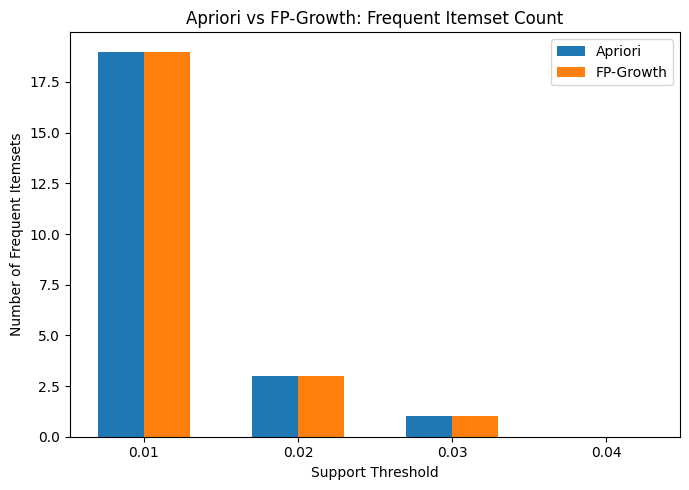

In [107]:
supports = ["0.01", "0.02", "0.03", "0.04"]
apriori_counts = [19, 3, 1, 0]
fpgrowth_counts = [19, 3, 1, 0]

x = range(len(supports))

plt.figure(figsize=(7,5))
plt.bar([i - 0.15 for i in x], apriori_counts, width=0.3, label="Apriori")
plt.bar([i + 0.15 for i in x], fpgrowth_counts, width=0.3, label="FP-Growth")

plt.xticks(x, supports)
plt.xlabel("Support Threshold")
plt.ylabel("Number of Frequent Itemsets")
plt.title("Apriori vs FP-Growth: Frequent Itemset Count")
plt.legend()
plt.tight_layout()
plt.show()

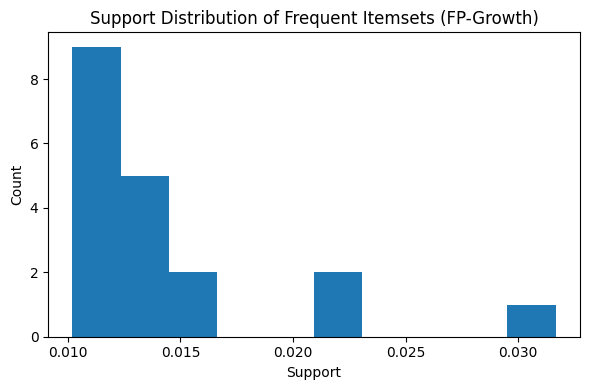

In [108]:
supports = list(fp_freq_itemsets.values())

plt.figure(figsize=(6,4))
plt.hist(supports, bins=10)
plt.xlabel("Support")
plt.ylabel("Count")
plt.title("Support Distribution of Frequent Itemsets (FP-Growth)")
plt.tight_layout()
plt.show()

The dataset is extremely sparse, with an average transaction length of only 1.1 items. Therefore, almost all transactions contain a single product, and meaningful co-occurrence patterns are nearly absent. Both Apriori and FP-Growth successfully identified frequent 1-itemsets, but neither algorithm discovered frequent 2-item or larger itemsets under the given support thresholds. Increasing the minimum support from 0.01 to 0.02 drastically reduced the number of frequent items, and at 0.05 no patterns remained. This demonstrates that the dataset does not support complex associations, and frequent item mining mostly highlights the most popular individual products rather than multi-item combinations